# Module 6, Session 1 — Where the Curve Comes From
### DS3323 · Tue Oct 20, 2026

**The claim we are testing today:** a network with *one* hidden layer
can approximate any continuous function on a closed interval, as closely as you
like, if you give it enough neurons.

Today, we are **building the approximation by hand** so you can see exactly where
the curve comes from. No optimizer until the last code block.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

def relu(z):
    return np.maximum(0, z)

In [3]:
relu(-10)

np.int64(0)

---
## 1. The function we are trying to learn


A marketing team spends money on ads. The first dollars work well. After a point,
the audience is saturated and each extra dollar returns less — eventually the
curve bends back toward zero.

- `x` = ad spend, in \$10k
- `y` = incremental revenue, in \$100k

**This is a continuous function on a closed interval.** That is a good example to understand the Universal Approximation Theorem.

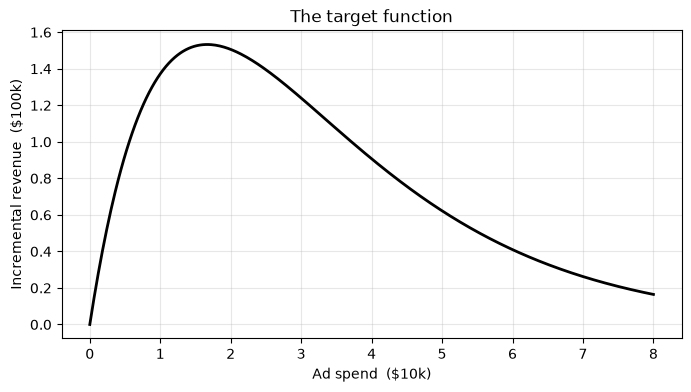

Peak return of 1.53 at a spend of 1.66


In [4]:
def f(x):
    # Incremental revenue as a function of ad spend.
    return 2.5 * x * np.exp(-0.6 * x)

x = np.linspace(0, 8, 400)

plt.figure(figsize=(8, 4))
plt.plot(x, f(x), lw=2, color="black")
plt.xlabel("Ad spend  ($10k)")
plt.ylabel("Incremental revenue  ($100k)")
plt.title("The target function")
plt.grid(alpha=.3)
plt.show()

print(f"Peak return of {f(x).max():.2f} at a spend of {x[f(x).argmax()]:.2f}")

**Question:** if you could only tell the marketing team
one number from this curve, which would it be? Hold that thought.

---
## 2. One neuron is a hinge

A single hidden neuron with a ReLU activation computes `relu(w*x + b)`.

This is not a curve. It is **a flat stretch and then a straight line**, joined at
one point. A "hinge".

Three parameters (we just looked at), and each does exactly one thing.

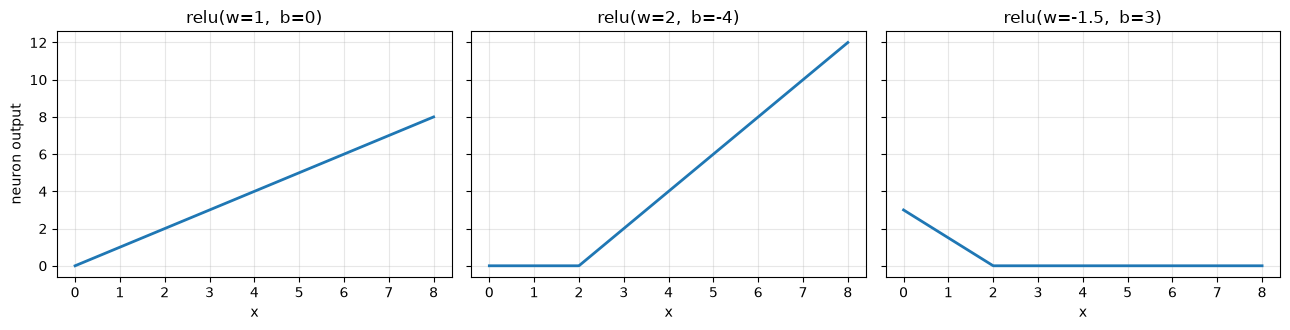

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
settings = [(1.0, 0.0, "w=1,  b=0"),
            (2.0, -4.0, "w=2,  b=-4"),
            (-1.5, 3.0, "w=-1.5,  b=3")]

for ax, (w, b, label) in zip(axes, settings):
    ax.plot(x, relu(w * x + b), lw=2)
    ax.set_title(f"relu({label})")
    ax.grid(alpha=.3)
    ax.set_xlabel("x")
axes[0].set_ylabel("neuron output")
plt.tight_layout()
plt.show()

Fill these in out loud before moving on:

- `w` controls ______
- `b` controls ______

---
## 3. Two hinges make a V

If one neuron is a hinge, two neurons are two hinges, and the output layer **adds
them together**.

Take `relu(x)` and `relu(-x)`. One is flat on the left and rising on the right.
The other is falling on the left and flat on the right. Add them.

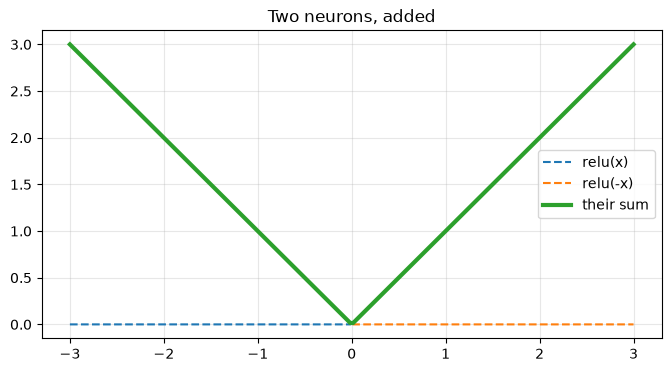

Is the sum exactly |x| ? True


In [6]:
xx = np.linspace(-3, 3, 200)

plt.figure(figsize=(8, 4))
plt.plot(xx, relu(xx), "--", label="relu(x)")
plt.plot(xx, relu(-xx), "--", label="relu(-x)")
plt.plot(xx, relu(xx) + relu(-xx), lw=3, label="their sum")
plt.legend()
plt.grid(alpha=.3)
plt.title("Two neurons, added")
plt.show()

print("Is the sum exactly |x| ?", np.allclose(relu(xx) + relu(-xx), np.abs(xx)))

Exactly `|x|`. 

**That is a two-neuron network solving a function in closed form, and you just
wrote it with no training at all.** The network does not need to be *taught* that hinges add
up; it needs to be taught *which* hinges.

---
## 4. The same thing, as an actual network

Let's prove the "hinge" is really what Keras is doing. We will build a network
with 2 hidden neurons and **set the weights by hand instead of training**.

Hidden layer: weights `[1, -1]`, biases `[0, 0]` → gives us `relu(x)` and `relu(-x)`
Output layer: weights `[1, 1]`, bias `0` → adds them

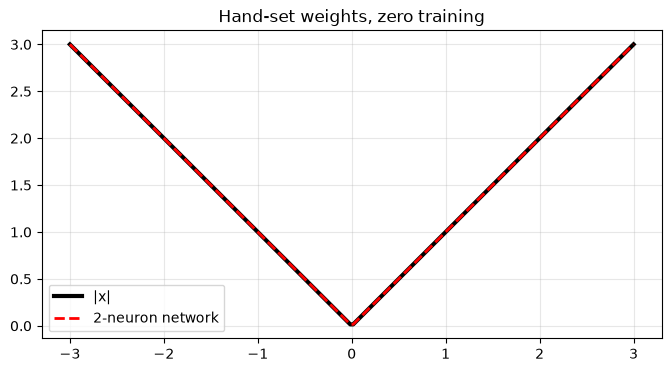

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

net = Sequential([
    Input(shape=(1,)),
    Dense(2, activation="relu"),
    Dense(1)
])

# Dense weights are shaped (inputs, units); biases are (units,)
net.layers[0].set_weights([np.array([[1.0, -1.0]]), np.array([0.0, 0.0])])
net.layers[1].set_weights([np.array([[1.0], [1.0]]), np.array([0.0])])

pred = net.predict(xx.reshape(-1, 1), verbose=0).ravel()

plt.figure(figsize=(8, 4))
plt.plot(xx, np.abs(xx), lw=3, color="black", label="|x|")
plt.plot(xx, pred, "--", lw=2, color="red", label="2-neuron network")
plt.legend(); plt.grid(alpha=.3)
plt.title("Hand-set weights, zero training")
plt.show()

---
## 5. Now build the business curve by hand

The ad-spend curve is not made of two straight pieces, so two hinges will not do
it. But the path to an equation does not change — **pick where you want the bends, then solve
for how much to bend.**

Say we put bends at x = 0, 1.5, 3, and 5. Between consecutive bends the
approximation is a straight line, so the slope of each segment is just rise over
run on the true curve. Each hinge only has to supply the *change* in slope from
the segment before it.

bend at x = [0.  1.5 3.  5. ]
slope change: [ 1.016 -1.206 -0.119  0.156]


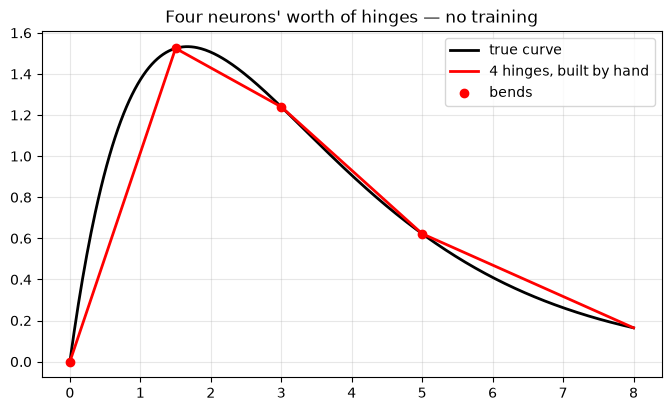

Worst error: 0.440


In [8]:
def hand_build(bends, lo=0.0, hi=8.0):
    # Return (prediction on x, hinge coefficients) for a piecewise-linear approximation that touches f() exactly at every bend.
    edges  = np.append(bends, hi)
    slopes = np.diff(f(edges)) / np.diff(edges)
    coefs  = np.diff(np.concatenate(([0.0], slopes)))   # change in slope at each bend
    pred   = f(lo) + sum(c * relu(x - k) for c, k in zip(coefs, bends))
    return pred, coefs

bends = np.array([0.0, 1.5, 3.0, 5.0])
pred4, coefs4 = hand_build(bends)

print("bend at x =", bends)
print("slope change:", np.round(coefs4, 3))

plt.figure(figsize=(8, 4.5))
plt.plot(x, f(x), lw=2, color="black", label="true curve")
plt.plot(x, pred4, lw=2, color="red", label="4 hinges, built by hand")
plt.scatter(bends, f(bends), color="red", zorder=5, label="bends")
plt.legend(); plt.grid(alpha=.3)
plt.title("Four neurons' worth of hinges — no training")
plt.show()

print(f"Worst error: {np.max(np.abs(pred4 - f(x))):.3f}")

**Look at where it is wrong.** The error is not spread evenly — it piles up where
the curve bends the most, and it is near zero on the  tail.

Universal Approximation Theorem takeaway: *a neuron is only useful where the
function changes direction.* More neurons give you more places to bend.

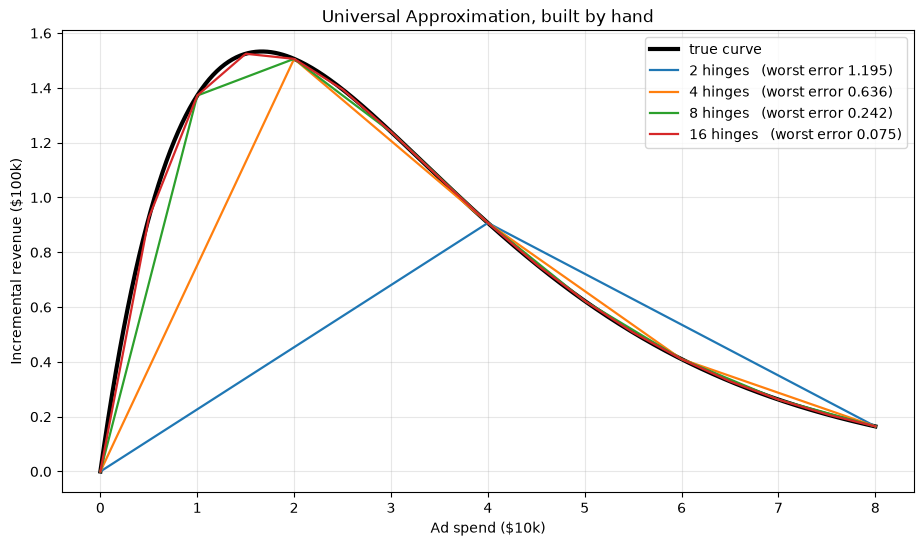

In [9]:
plt.figure(figsize=(11, 6))
plt.plot(x, f(x), lw=3, color="black", label="true curve")

for k in [2, 4, 8, 16]:
    kn = np.linspace(0, 8, k + 1)[:-1]
    p, _ = hand_build(kn)
    plt.plot(x, p, lw=1.6, label=f"{k} hinges   (worst error {np.max(np.abs(p - f(x))):.3f})")

plt.legend(); plt.grid(alpha=.3)
plt.title("Universal Approximation, built by hand")
plt.xlabel("Ad spend ($10k)"); plt.ylabel("Incremental revenue ($100k)")
plt.show()

| hinges | worst error |
|---|---|
| 2 | 1.195 |
| 4 | 0.636 |
| 8 | 0.242 |
| 16 | 0.075 |

**This is the Universal Approximation Theorem (and we never trained anything).**

For any error
tolerance, there is *some* number of neurons that gets under it. The
table illustrates the theorem. 

---
## 6. So what is training for?

Everything above required us to already know the answer. We used `f()` itself to
work out where the bends go.

In real work you do not have `f()`. You have data points and no formula. Training
is the search for those bend locations and slope changes **from the data alone**.

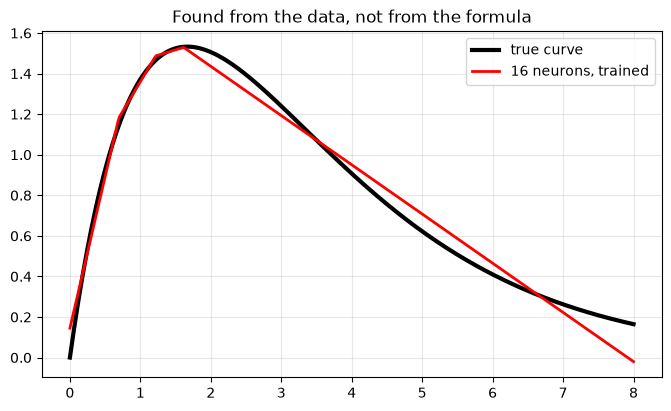

Worst error: 0.185
Final loss:  0.00509


In [10]:
from tensorflow.keras.optimizers import Adam

X = x.reshape(-1, 1)
y = f(x)

model = Sequential([
    Input(shape=(1,)),
    Dense(16, activation="relu"),
    Dense(1)
])
model.compile(optimizer=Adam(learning_rate=0.01), loss="mse")
history = model.fit(X, y, epochs=1500, batch_size=64, verbose=0)   # ~30-45 seconds

y_pred = model.predict(X, verbose=0).ravel()

plt.figure(figsize=(8, 4.5))
plt.plot(x, y, lw=3, color="black", label="true curve")
plt.plot(x, y_pred, lw=2, color="red", label="16 neurons, trained")
plt.legend(); plt.grid(alpha=.3)
plt.title("Found from the data, not from the formula")
plt.show()

print(f"Worst error: {np.max(np.abs(y_pred - y)):.3f}")
print(f"Final loss:  {history.history['loss'][-1]:.5f}")

Compare that worst-error number to the hand-built 16-hinge row in the table.

If the trained net is **worse** than the hand-built one with the same # hinges,this is critical to understanding UAT. The hinges it
*could* have found exist. Whether the optimizer actually finds them is a separate
question, and the theorem says nothing about it.

---
## Your Turn

1. Where did the trained model put its bends? Is there a way to find out from
   `model.layers[0].get_weights()`? Try it.
2. If you doubled the width to 32, what would you predict happens to the worst
   error — and what would you predict happens to the *training time*? Try it.

In [11]:
model.layers[0].get_weights()

[array([[ 0.5785922 ,  0.37770164, -0.29488027, -0.11160675,  0.75617313,
         -0.48594677, -0.1700711 ,  0.40932107,  0.54742026, -0.40214005,
         -0.27370837, -0.03585064, -0.02752966,  0.6401847 ,  0.70205647,
          0.7671643 ]], dtype=float32),
 array([ 0.00320482,  0.00228351,  0.        ,  0.        , -1.2207772 ,
         0.        ,  0.        ,  0.0041779 ,  0.00250964,  0.        ,
         0.        ,  0.        ,  0.        , -0.44432274, -0.8548845 ,
         0.00254024], dtype=float32)]

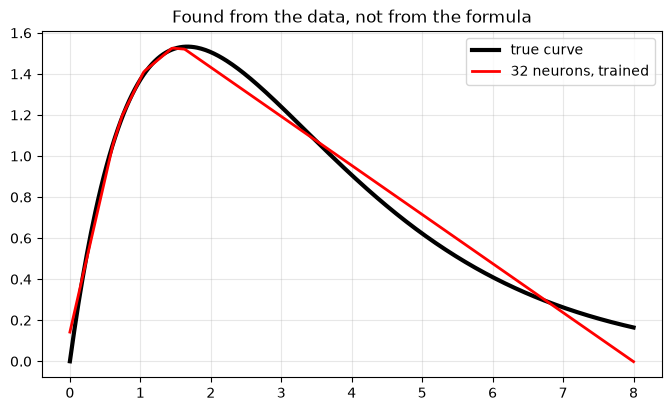

Worst error: 0.166
Final loss:  0.00738


In [12]:
X = x.reshape(-1, 1)
y = f(x)

model = Sequential([
    Input(shape=(1,)),
    Dense(32, activation="relu"),
    Dense(1)
])
model.compile(optimizer=Adam(learning_rate=0.01), loss="mse")
history = model.fit(X, y, epochs=1500, batch_size=64, verbose=0)   # ~30-45 seconds

y_pred = model.predict(X, verbose=0).ravel()

plt.figure(figsize=(8, 4.5))
plt.plot(x, y, lw=3, color="black", label="true curve")
plt.plot(x, y_pred, lw=2, color="red", label="32 neurons, trained")
plt.legend(); plt.grid(alpha=.3)
plt.title("Found from the data, not from the formula")
plt.show()

print(f"Worst error: {np.max(np.abs(y_pred - y)):.3f}")
print(f"Final loss:  {history.history['loss'][-1]:.5f}")